# 2. ¿Qué tan pobre es el Chocó, municipio por municipio?

Aquí se mira la **incidencia** del IPM (el % de personas en hogares pobres) en los 30 municipios del Chocó,
cómo se comparan con el resto del país y qué tan distinta es la cabecera de la zona rural.

In [1]:
# Preparación: ubica la carpeta del repo y carga el paquete del estudio
import sys
from pathlib import Path

RAIZ = Path.cwd().resolve()
for _ in range(5):
    if (RAIZ / "src" / "pobreza").exists():
        break
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pobreza import datos, ipm
from pobreza.config import ETIQUETAS, IPM_INDICADORES, DIMENSIONES, PACIFICO, REPORTES
from pobreza.graficos import CHOCO, RESTO, ACENTO, NEUTRO, DIMENSION_COLORES, estilo, guardar, fuente

estilo()
pd.set_option("display.float_format", lambda x: f"{x:,.1f}")
pd.set_option("display.max_columns", 40)

In [2]:
base = datos.base_municipal()
choco = base[base.es_choco].sort_values("ipm", ascending=False)
resto = base[~base.es_choco]

mediana_pais = base["ipm"].median()
print(f"Mediana municipal del país: {mediana_pais:.1f} %")
print(f"Mediana del Chocó:          {choco['ipm'].median():.1f} %")
print(f"Municipio menos pobre del Chocó: {choco.iloc[-1]['municipio']} ({choco.iloc[-1]['ipm']:.1f} %)")
print(f"Municipio más pobre del Chocó:   {choco.iloc[0]['municipio']} ({choco.iloc[0]['ipm']:.1f} %)")

Mediana municipal del país: 40.8 %
Mediana del Chocó:          68.2 %
Municipio menos pobre del Chocó: Quibdó (44.4 %)
Municipio más pobre del Chocó:   Alto Baudó (90.6 %)


## 2.1 Los 30 municipios, ordenados

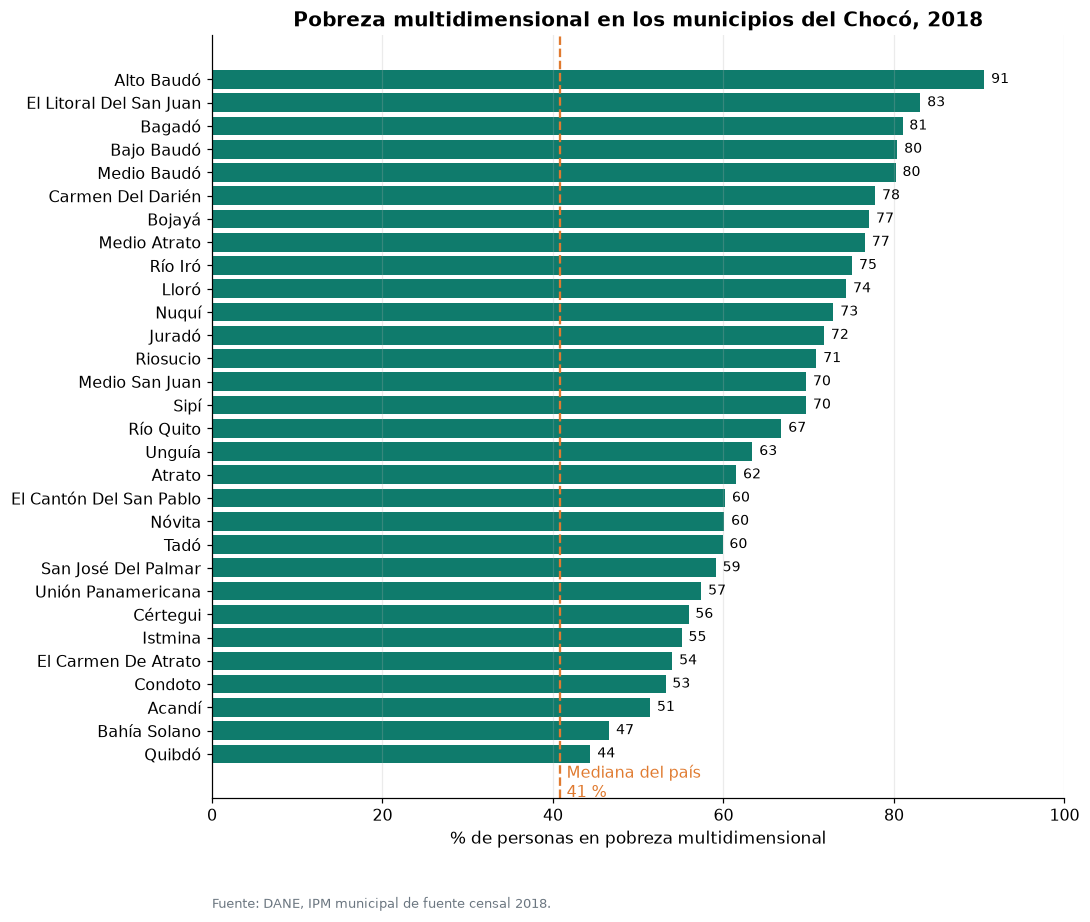

In [3]:
fig, ax = plt.subplots(figsize=(10, 9))
ax.barh(choco["municipio"], choco["ipm"], color=CHOCO)
ax.axvline(mediana_pais, color=ACENTO, ls="--", lw=1.5)
ax.text(mediana_pais + 0.8, len(choco) - 0.6, f"Mediana del país\n{mediana_pais:.0f} %", color=ACENTO, va="top")
ax.invert_yaxis()
ax.set(xlabel="% de personas en pobreza multidimensional", xlim=(0, 100),
       title="Pobreza multidimensional en los municipios del Chocó, 2018")
for y, v in enumerate(choco["ipm"]):
    ax.text(v + 0.8, y, f"{v:.0f}", va="center", fontsize=9)
ax.grid(axis="y", visible=False)
fuente(ax, "DANE, IPM municipal de fuente censal 2018.")
guardar(fig, "02_ranking_choco")
plt.show()

## 2.2 El Chocó dentro del país

¿Dónde caen los municipios del Chocó en la distribución nacional? Cada punto es un municipio.

De los 100 municipios más pobres del país, 16 son del Chocó (el Chocó tiene 30 de 1122 municipios, el 2.7 %).
27 de 30 municipios chocoanos están en el 25 % más pobre del país.


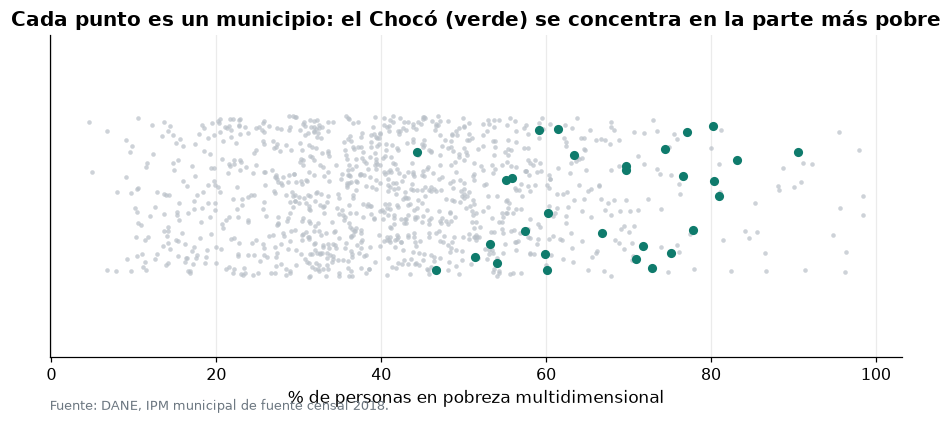

In [4]:
base["percentil_pais"] = base["ipm"].rank(pct=True) * 100
choco = choco.merge(base[["cod_mpio", "percentil_pais"]], on="cod_mpio")
n_top = 100
top = base.nlargest(n_top, "ipm")
print(f"De los {n_top} municipios más pobres del país, {int(top['es_choco'].sum())} son del Chocó "
      f"(el Chocó tiene {len(choco)} de {len(base)} municipios, el {100 * len(choco) / len(base):.1f} %).")
print(f"{(choco['percentil_pais'] >= 75).sum()} de {len(choco)} municipios chocoanos están en el 25 % más pobre del país.")

fig, ax = plt.subplots(figsize=(10, 3.8))
sns.stripplot(x=resto["ipm"], color=RESTO, size=3, jitter=0.25, ax=ax, alpha=0.7)
sns.stripplot(x=choco["ipm"], color=CHOCO, size=6, jitter=0.25, ax=ax)
ax.set(xlabel="% de personas en pobreza multidimensional", yticks=[],
       title="Cada punto es un municipio: el Chocó (verde) se concentra en la parte más pobre")
fuente(ax, "DANE, IPM municipal de fuente censal 2018.")
guardar(fig, "02_distribucion_pais")
plt.show()

## 2.3 Cabecera contra zona rural

En casi todo el país la zona rural es más pobre que la cabecera. La pregunta es **cuánto** más en el Chocó,
y si hay municipios donde incluso la cabecera está por encima de la mediana rural del país.

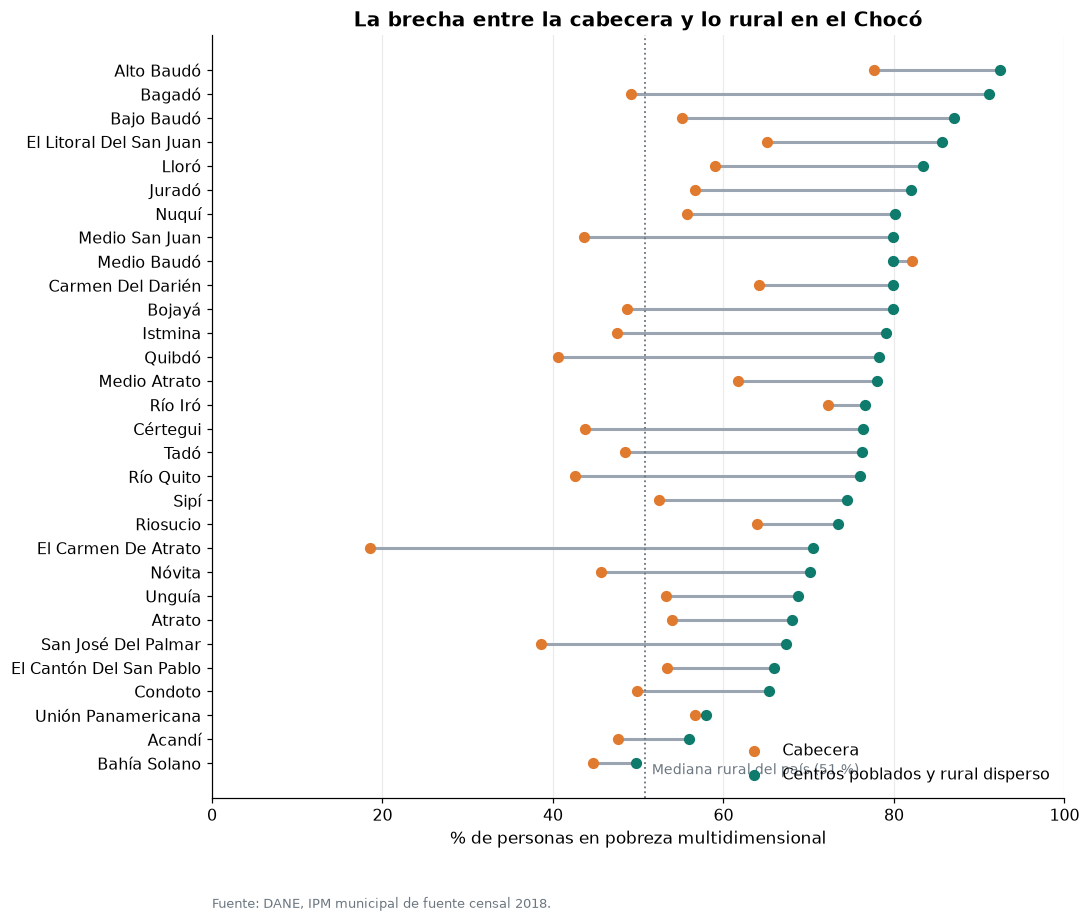

Brecha rural - cabecera (mediana): Chocó 23.2 pp · país 22.1 pp
Cabeceras chocoanas por encima de la mediana RURAL del país: 16 de 30


In [5]:
if {"ipm_cabecera", "ipm_rural"} <= set(base.columns):
    dumb = choco.dropna(subset=["ipm_cabecera", "ipm_rural"]).sort_values("ipm_rural")
    fig, ax = plt.subplots(figsize=(10, 9))
    ax.hlines(dumb["municipio"], dumb["ipm_cabecera"], dumb["ipm_rural"], color="#9aa5b1", lw=2)
    ax.scatter(dumb["ipm_cabecera"], dumb["municipio"], color=ACENTO, s=40, label="Cabecera", zorder=3)
    ax.scatter(dumb["ipm_rural"], dumb["municipio"], color=CHOCO, s=40, label="Centros poblados y rural disperso", zorder=3)
    med_rural = base["ipm_rural"].median()
    ax.axvline(med_rural, color="#6b7680", ls=":", lw=1.2)
    ax.text(med_rural + 0.8, -0.6, f"Mediana rural del país ({med_rural:.0f} %)", color="#6b7680", fontsize=9, va="bottom")
    ax.set(xlabel="% de personas en pobreza multidimensional", xlim=(0, 100),
           title="La brecha entre la cabecera y lo rural en el Chocó")
    ax.legend(loc="lower right")
    ax.grid(axis="y", visible=False)
    fuente(ax, "DANE, IPM municipal de fuente censal 2018.")
    guardar(fig, "02_cabecera_rural")
    plt.show()

    brecha_ch = (dumb["ipm_rural"] - dumb["ipm_cabecera"]).median()
    brecha_pais = (base["ipm_rural"] - base["ipm_cabecera"]).median()
    print(f"Brecha rural - cabecera (mediana): Chocó {brecha_ch:.1f} pp · país {brecha_pais:.1f} pp")
    print(f"Cabeceras chocoanas por encima de la mediana RURAL del país: "
          f"{(dumb['ipm_cabecera'] > med_rural).sum()} de {len(dumb)}")

## 2.4 De porcentajes a personas

Un porcentaje alto en un municipio pequeño pesa distinto que uno medio en un municipio grande.
Con la población del censo se estima **cuántas personas** viven en hogares pobres.

In [6]:
if "personas_pobres_ipm" in base:
    pc = choco.merge(base[["cod_mpio", "personas_pobres_ipm", "poblacion_total"]], on="cod_mpio",
                     suffixes=("", "_b")).sort_values("personas_pobres_ipm", ascending=False)
    total_pobres = pc["personas_pobres_ipm"].sum()
    pc["% del total del Chocó"] = 100 * pc["personas_pobres_ipm"] / total_pobres
    pc["acumulado %"] = pc["% del total del Chocó"].cumsum()
    print(f"Personas en pobreza multidimensional en el Chocó (estimado 2018): {total_pobres:,.0f}")
    print(f"Tasa departamental ponderada por población: {100 * total_pobres / pc['poblacion_total'].sum():.1f} %")
    display(pc[["municipio", "poblacion_total", "ipm", "personas_pobres_ipm", "% del total del Chocó",
                "acumulado %"]].head(12).reset_index(drop=True))

Personas en pobreza multidimensional en el Chocó (estimado 2018): 340,267
Tasa departamental ponderada por población: 63.6 %


,municipio,poblacion_total,ipm,personas_pobres_ipm,% del total del Chocó,acumulado %
0,Quibdó,"129,237.0",44.4,"57,381.0",16.9,16.9
1,Riosucio,"53,449.0",70.9,"37,895.0",11.1,28.0
2,Alto Baudó,"27,584.0",90.6,"24,991.0",7.3,35.3
3,Bajo Baudó,"29,957.0",80.4,"24,085.0",7.1,42.4
4,El Litoral Del San Juan,"21,669.0",83.1,"18,007.0",5.3,47.7
5,Istmina,"30,742.0",55.1,"16,939.0",5.0,52.7
6,Carmen Del Darién,"18,433.0",77.8,"14,341.0",4.2,56.9
7,Medio Baudó,"15,109.0",80.2,"12,117.0",3.6,60.5
8,Nuquí,"16,223.0",72.9,"11,827.0",3.5,63.9
9,Tadó,"18,011.0",59.9,"10,789.0",3.2,67.1


## 2.5 Mapa

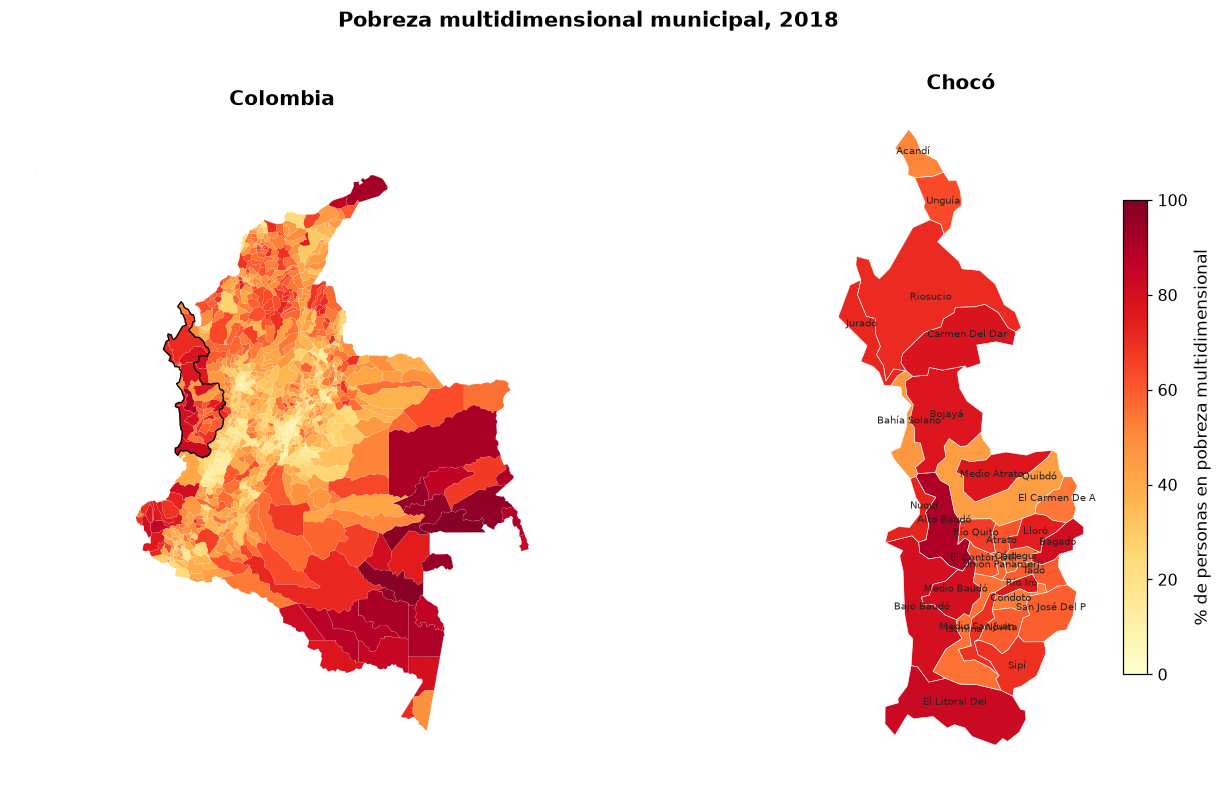

In [7]:
mapa = datos.mapa_municipios()
if mapa is None:
    print("No hay mapa disponible (falta el GeoJSON o geopandas).")
else:
    g = mapa.merge(base[["cod_mpio", "ipm", "es_choco", "municipio"]], on="cod_mpio", how="left")
    fig, axes = plt.subplots(1, 2, figsize=(14, 8), gridspec_kw={"width_ratios": [1, 1]})
    g.plot(column="ipm", cmap="YlOrRd", vmin=0, vmax=100, linewidth=0.05, edgecolor="white", ax=axes[0],
           missing_kwds={"color": "#eeeeee"})
    g[g["es_choco"] == True].dissolve().boundary.plot(ax=axes[0], color="black", lw=0.9)  # noqa: E712
    axes[0].set_title("Colombia")
    gc = g[g["es_choco"] == True]  # noqa: E712
    gc.plot(column="ipm", cmap="YlOrRd", vmin=0, vmax=100, linewidth=0.4, edgecolor="white", ax=axes[1],
            legend=True, legend_kwds={"label": "% de personas en pobreza multidimensional", "shrink": 0.7})
    for _, fila in gc.iterrows():
        p = fila.geometry.representative_point()
        axes[1].annotate(str(fila["municipio"])[:14], (p.x, p.y), fontsize=6.5, ha="center", color="#222")
    axes[1].set_title("Chocó")
    for a in axes:
        a.set_axis_off()
    fig.suptitle("Pobreza multidimensional municipal, 2018", fontweight="bold", fontsize=14)
    guardar(fig, "02_mapa")
    plt.show()

## Para llevar

- El Chocó no tiene "un" nivel de pobreza: hay diferencias grandes entre municipios, y sobre todo entre la
  cabecera y la zona rural de un mismo municipio.
- Aun así, la mayoría de sus municipios cae en la parte más pobre del país, y varias **cabeceras** del Chocó
  tienen más pobreza que la zona rural típica de Colombia.
- Para focalizar, el porcentaje y el número de personas cuentan historias distintas: conviene mirar los dos.